# 1. Data Preparation for Alzheimer’s disease dataset

This notebook is part of the reproduction workflow for Figure 2, **“SpatialZoomer reveals the Alzheimer’s disease progression signal at specific scales.”**

The full workflow includes three notebooks:

1. Data preparation, including data integration and preprocessing  (Current notebook)
2. Multi-scale analysis using SpatialZoomer  
3. Downstream analysis of AD progression-related signals  

The raw data should be downloaded from the official 10x Genomics website:  
https://www.10xgenomics.com/datasets/xenium-in-situ-analysis-of-alzheimers-disease-mouse-model-brain-coronal-sections-from-one-hemisphere-over-a-time-course-1-standard

The raw data were then processed with `SpatialData` and saved in `.zarr` format.

This dataset contains **six mouse brain samples** profiled using the Xenium v1 platform with a 347-gene panel. It includes both wild-type samples (**WT1, WT2, and WT3**) and TgCRND8 Alzheimer’s disease mouse model samples (**Tg1, Tg2, and Tg3**) collected at three time points, corresponding to mild, moderate, and advanced stages of amyloid-beta (Aβ) deposition.

The tutorial can be completed on a standard personal computer in approximately 2-3 minutes.

In [1]:
import warnings
warnings.filterwarnings("ignore")

import squidpy as sq
import scanpy as sc
import spatialdata as sd
from pathlib import Path
import anndata as ad
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
import os
from collections import Counter

# default figure settings
plt.rcParams.update({
    "font.family":'sans-serif',
    "mathtext.fontset":'stix',
    "font.size": 7,
    'pdf.fonttype': 42,
    "figure.dpi": 100,      
    "savefig.dpi": 300     
    })

sc.settings.set_figure_params(dpi=150)

In [2]:
runLabel = 'Xenium_V1_AD_Merged'
save_path = "./" 
Path(save_path).mkdir(parents=True, exist_ok=True)


data_path = "E:/SpatialZoomer/Data/Dynamics/"

runLabel_w1 = 'Xenium_V1_FFPE_wildtype_2_5_months' 
xenium_path_w1 = data_path + runLabel_w1 + ".zarr"

runLabel_w2 = 'Xenium_V1_FFPE_wildtype_5_7_months' 
xenium_path_w2 = data_path + runLabel_w2 + ".zarr"

runLabel_w3 = 'Xenium_V1_FFPE_wildtype_13_4_months' 
xenium_path_w3 = data_path + runLabel_w3 + ".zarr"

runLabel_t1 = 'Xenium_V1_FFPE_TgCRND8_2_5_months' 
xenium_path_t1 = data_path + runLabel_t1 + ".zarr"

runLabel_t2 = 'Xenium_V1_FFPE_TgCRND8_5_7_months' 
xenium_path_t2 = data_path + runLabel_t2 + ".zarr"

runLabel_t3 = 'Xenium_V1_FFPE_TgCRND8_17_9_months' 
xenium_path_t3 = data_path + runLabel_t3 + ".zarr"

In [3]:
sdata_w1 = sd.read_zarr(xenium_path_w1)
sdata_w2 = sd.read_zarr(xenium_path_w2)
sdata_w3 = sd.read_zarr(xenium_path_w3)

sdata_t1 = sd.read_zarr(xenium_path_t1)
sdata_t2 = sd.read_zarr(xenium_path_t2)
sdata_t3 = sd.read_zarr(xenium_path_t3)

print(sdata_w1['table'].shape)
print(sdata_w2['table'].shape)
print(sdata_w3['table'].shape)
print(sdata_t1['table'].shape)
print(sdata_t2['table'].shape)
print(sdata_t3['table'].shape)

(58231, 347)
(58685, 347)
(59935, 347)
(53913, 347)
(58682, 347)
(62268, 347)


In [4]:
adata_w1 = sdata_w1["table"].copy()
adata_w2 = sdata_w2["table"].copy()
adata_w3 = sdata_w3["table"].copy()
adata_t1 = sdata_t1["table"].copy()
adata_t2 = sdata_t2["table"].copy()
adata_t3 = sdata_t3["table"].copy()
del sdata_w1
del sdata_w2
del sdata_w3
del sdata_t1
del sdata_t2
del sdata_t3

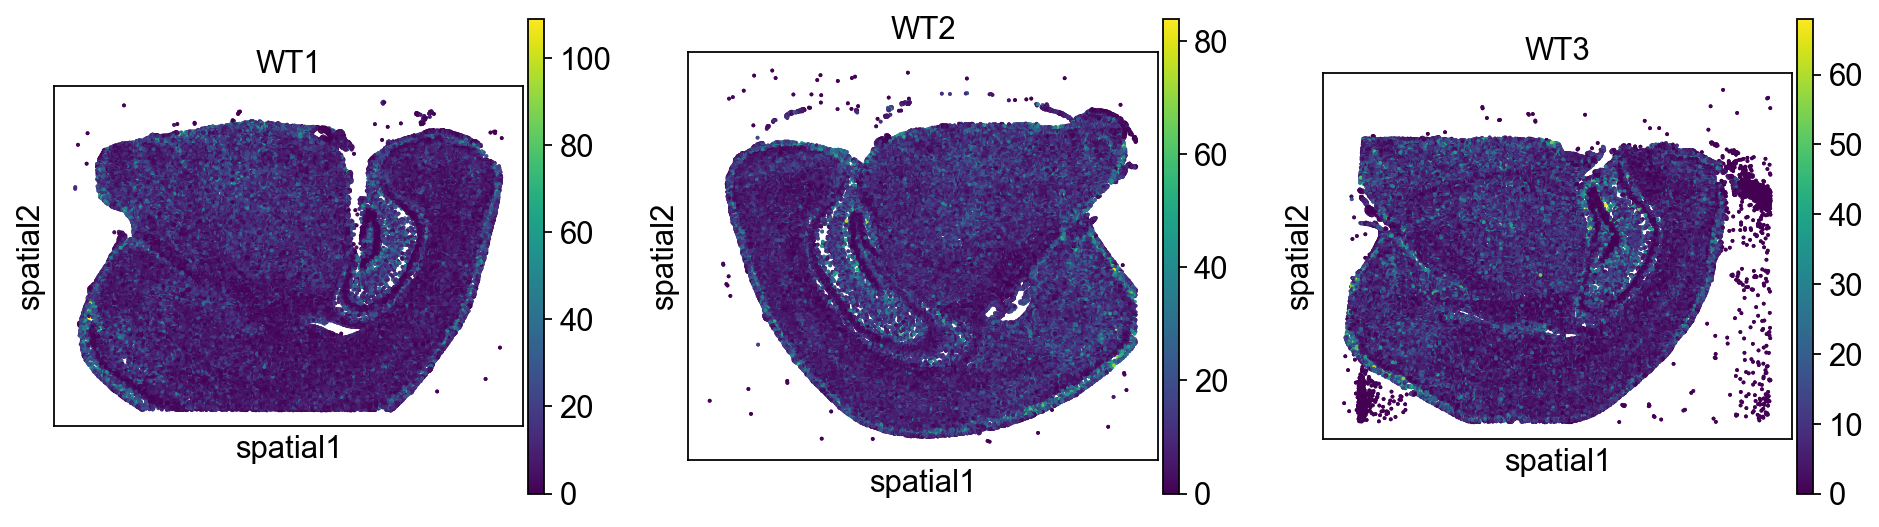

In [5]:
import matplotlib.pyplot as plt

sc.settings.set_figure_params(dpi=80)

fig, axes = plt.subplots(1, 3, figsize=(12, 3.5))

sq.pl.spatial_scatter(
    adata_w1,
    color="Apoe",
    library_id="spatial",
    shape=None,
    ax=axes[0],
)

sq.pl.spatial_scatter(
    adata_w2,
    color="Apoe",
    library_id="spatial",
    shape=None,
    ax=axes[1],
)

sq.pl.spatial_scatter(
    adata_w3,
    color="Apoe",
    library_id="spatial",
    shape=None,
    ax=axes[2],
)

axes[0].set_title("WT1")
axes[1].set_title("WT2")
axes[2].set_title("WT3")

plt.tight_layout()
plt.show()

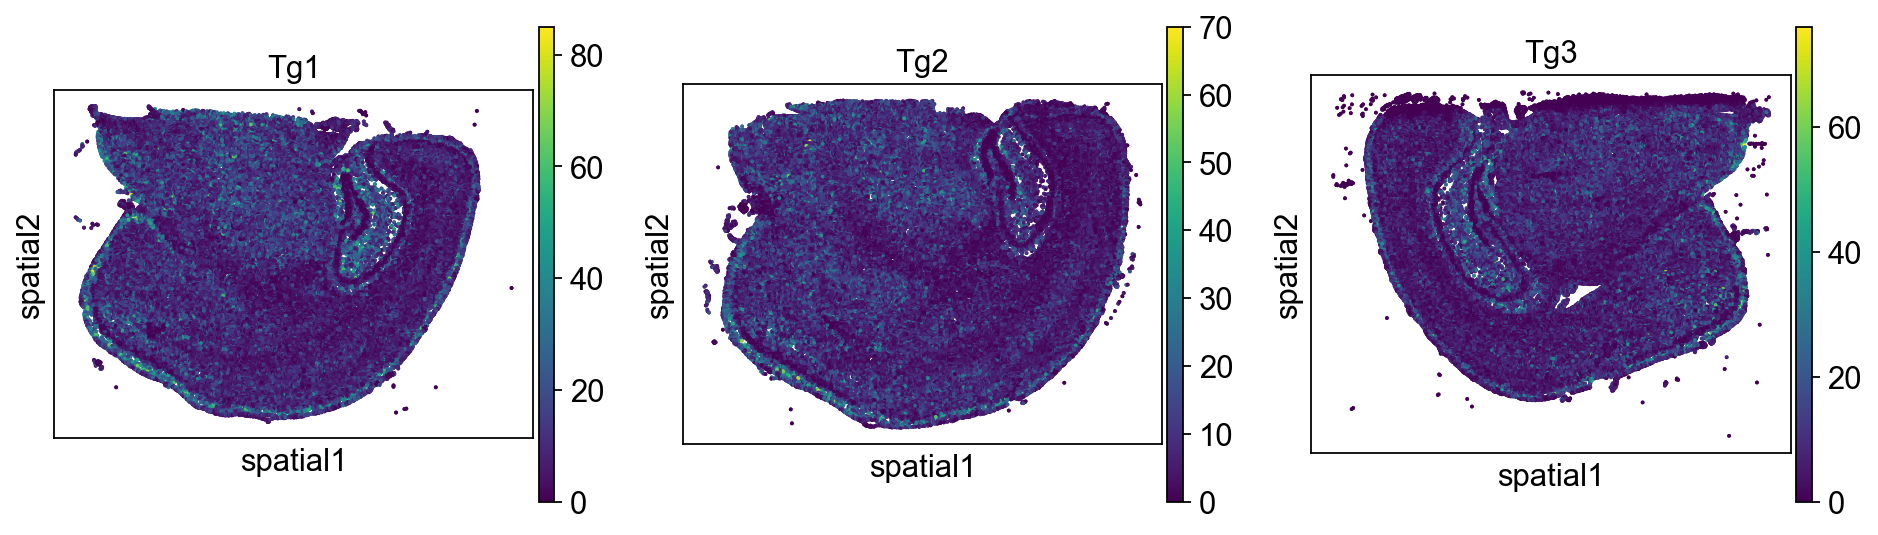

In [6]:
import matplotlib.pyplot as plt

sc.settings.set_figure_params(dpi=80)

fig, axes = plt.subplots(1, 3, figsize=(12, 3.5))

sq.pl.spatial_scatter(
    adata_t1,
    color="Apoe",
    library_id="spatial",
    shape=None,
    ax=axes[0],
)

sq.pl.spatial_scatter(
    adata_t2,
    color="Apoe",
    library_id="spatial",
    shape=None,
    ax=axes[1],
)

sq.pl.spatial_scatter(
    adata_t3,
    color="Apoe",
    library_id="spatial",
    shape=None,
    ax=axes[2],
)

axes[0].set_title("Tg1")
axes[1].set_title("Tg2")
axes[2].set_title("Tg3")

plt.tight_layout()
plt.show()

## Stitching Samples into a Shared Spatial Space

The six samples are placed in a shared coordinate space through rotation and translation. Sufficient gaps are kept between samples to avoid cross-sample edges in the subsequent spatial nearest-neighbor graph.

In [7]:
adata_w1.obsm["spatial_raw"] = adata_w1.obsm["spatial"].copy()
adata_w2.obsm["spatial_raw"] = adata_w2.obsm["spatial"].copy()
adata_w3.obsm["spatial_raw"] = adata_w3.obsm["spatial"].copy()
adata_t1.obsm["spatial_raw"] = adata_t1.obsm["spatial"].copy()
adata_t2.obsm["spatial_raw"] = adata_t2.obsm["spatial"].copy()
adata_t3.obsm["spatial_raw"] = adata_t3.obsm["spatial"].copy()

spatial_w1 = adata_w1.obsm["spatial_raw"].copy()
spatial_w2 = adata_w2.obsm["spatial_raw"].copy()
spatial_w3 = adata_w3.obsm["spatial_raw"].copy()
spatial_t1 = adata_t1.obsm["spatial_raw"].copy()
spatial_t2 = adata_t2.obsm["spatial_raw"].copy()
spatial_t3 = adata_t3.obsm["spatial_raw"].copy()

In [8]:
var_names = adata_w1.var_names.intersection(adata_t1.var_names)
len(var_names)

347

In [9]:
# Flip selected samples along the x-axis for better alignment
spatial_w2[:, 0] = np.max(spatial_w2[:, 0]) - spatial_w2[:, 0] + np.min(spatial_w2[:, 0])
spatial_t3[:, 0] = np.max(spatial_t3[:, 0]) - spatial_t3[:, 0] + np.min(spatial_t3[:, 0])

# Set a large padding distance to avoid cross-sample spatial connections
padding = 1000

# Place WT2/TgCRND82 to the right of WT1/TgCRND81
max_x1 = np.max([spatial_w1[:, 0].max(axis=0), spatial_t1[:, 0].max(axis=0)])
offset_x2 = max_x1 + padding
spatial_w2[:, 0] = spatial_w2[:, 0] + offset_x2
spatial_t2[:, 0] = spatial_t2[:, 0] + offset_x2

# Place WT3/TgCRND83 to the right of WT2/TgCRND82
max_x2 = np.max([spatial_w2[:, 0].max(axis=0), spatial_t2[:, 0].max(axis=0)])
offset_x3 = max_x2 + padding
spatial_w3[:, 0] = spatial_w3[:, 0] + offset_x3
spatial_t3[:, 0] = spatial_t3[:, 0] + offset_x3

# Place TgCRND8 samples below the corresponding WT samples
max_y = np.max([
    spatial_w1[:, 1].max(axis=0),
    spatial_w2[:, 1].max(axis=0),
    spatial_w3[:, 1].max(axis=0),
])
offset_y = max_y + padding
spatial_t1[:, 1] = spatial_t1[:, 1] + offset_y
spatial_t2[:, 1] = spatial_t2[:, 1] + offset_y
spatial_t3[:, 1] = spatial_t3[:, 1] + offset_y

# Update spatial coordinates in each AnnData object
adata_w1.obsm["spatial"] = spatial_w1.copy()
adata_w2.obsm["spatial"] = spatial_w2.copy()
adata_w3.obsm["spatial"] = spatial_w3.copy()
adata_t1.obsm["spatial"] = spatial_t1.copy()
adata_t2.obsm["spatial"] = spatial_t2.copy()
adata_t3.obsm["spatial"] = spatial_t3.copy()

# Keep the shared gene set across all samples
adata_w1 = adata_w1[:, var_names]
adata_w2 = adata_w2[:, var_names]
adata_w3 = adata_w3[:, var_names]
adata_t1 = adata_t1[:, var_names]
adata_t2 = adata_t2[:, var_names]
adata_t3 = adata_t3[:, var_names]

In [10]:
# Add sample-specific suffixes to cell names for each AnnData object
adata_w1.obs_names = adata_w1.obs_names + '_WT1'
adata_w2.obs_names = adata_w2.obs_names + '_WT2'
adata_w3.obs_names = adata_w3.obs_names + '_WT3'
adata_t1.obs_names = adata_t1.obs_names + '_TgCRND81'
adata_t2.obs_names = adata_t2.obs_names + '_TgCRND82'
adata_t3.obs_names = adata_t3.obs_names + '_TgCRND83'

# Concatenate all AnnData objects
adata = ad.concat(
    [adata_w1, adata_w2, adata_w3, adata_t1, adata_t2, adata_t3],
    axis=0,  # Concatenate cells by rows
    join='inner',  # Use the intersection of genes to ensure a shared gene set across all samples
    label='batch',  # Add a new observation column to indicate the sample origin
    keys=['WT1', 'WT2', 'WT3', 'TgCRND81', 'TgCRND82', 'TgCRND83']  # Sample labels
)
adata

AnnData object with n_obs × n_vars = 351714 × 347
    obs: 'cell_id', 'transcript_counts', 'control_probe_counts', 'control_codeword_counts', 'unassigned_codeword_counts', 'total_counts', 'cell_area', 'nucleus_area', 'region', 'cell_labels', 'batch'
    obsm: 'spatial', 'spatial_raw'

In [11]:
Counter(adata.obs["batch"])

Counter({'TgCRND83': 62268,
         'WT3': 59935,
         'WT2': 58685,
         'TgCRND82': 58682,
         'WT1': 58231,
         'TgCRND81': 53913})

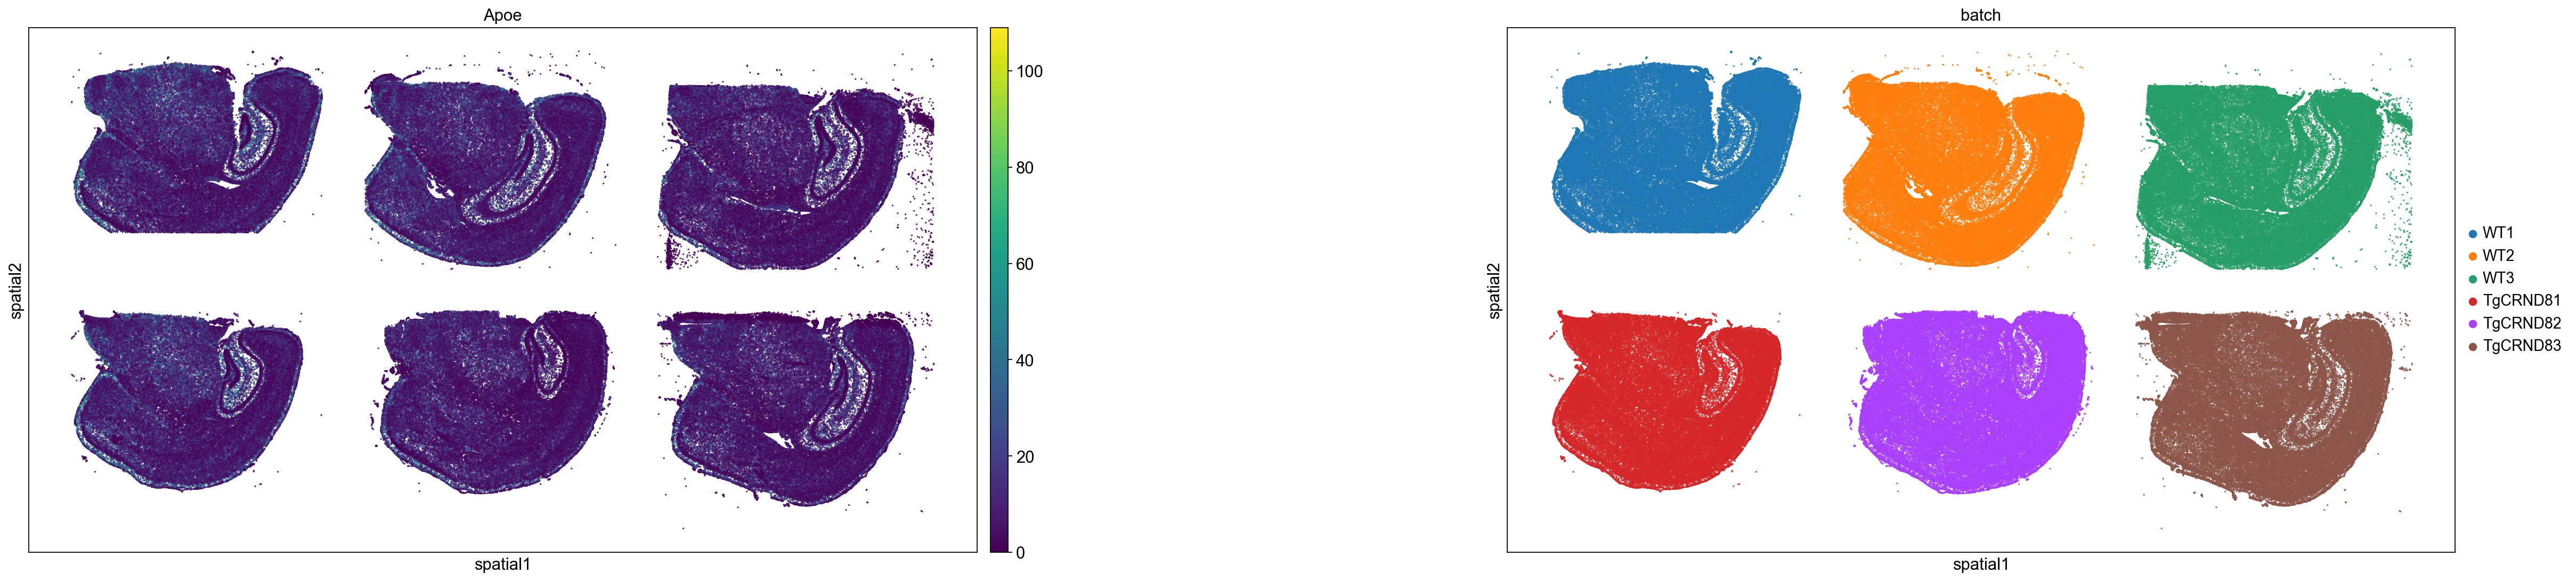

In [12]:
sq.pl.spatial_scatter(adata, 
                      color=["Apoe", "batch"], 
                      library_id="spatial",
                      shape=None,
                      figsize=(18, 8))

## Cell and gene quality control

In [13]:
import spatialzoomer as sz

<Axes: title={'center': 'Nucleus ratio'}, ylabel='Count'>

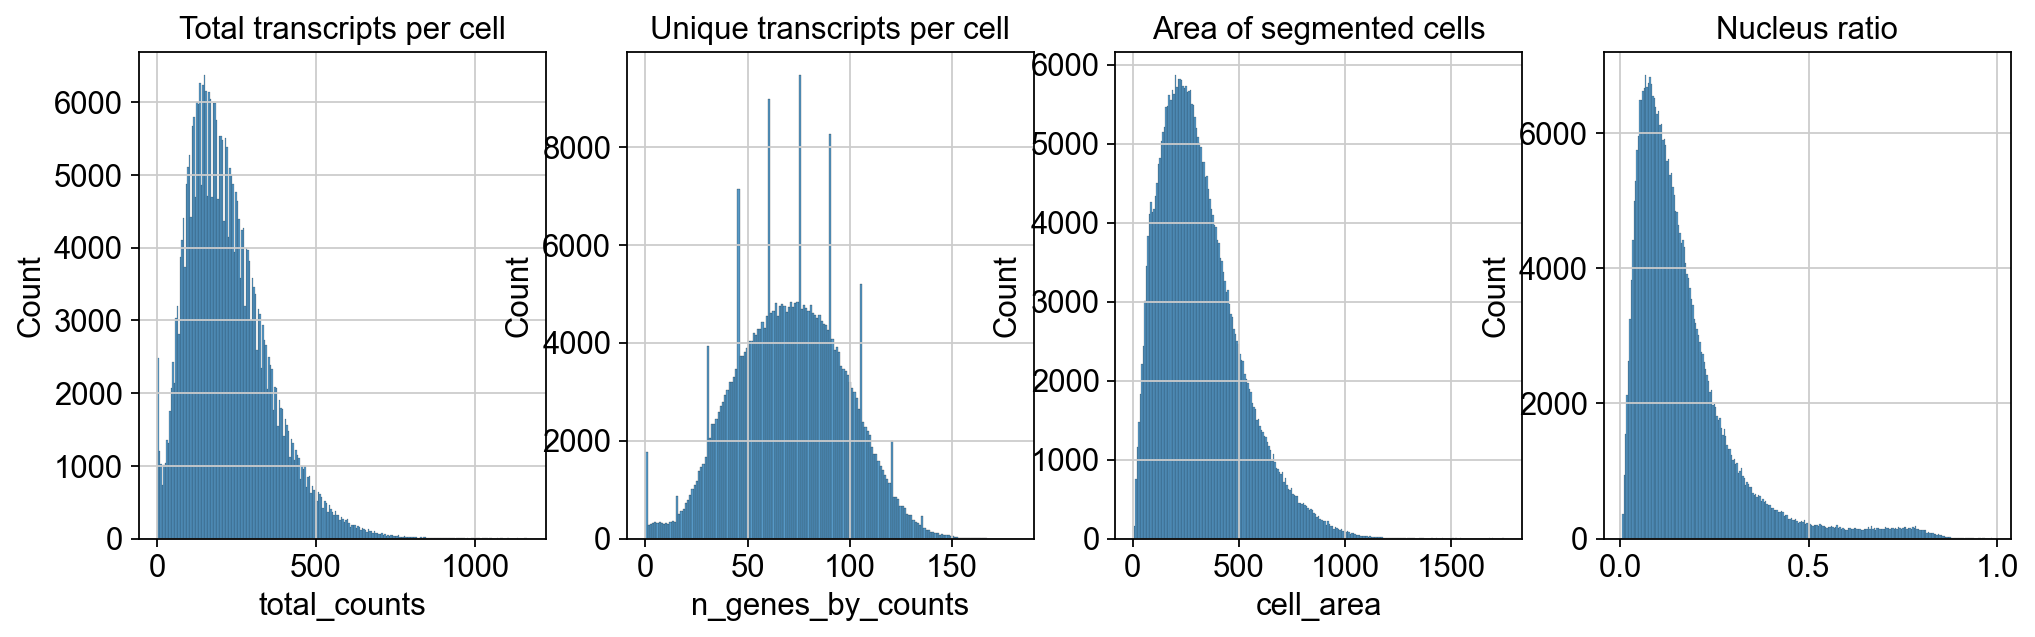

In [14]:
sc.pp.calculate_qc_metrics(adata, percent_top=(10, 20, 50, 150), inplace=True)
fig, axs = plt.subplots(1, 4, figsize=(15, 4))

axs[0].set_title("Total transcripts per cell")
sns.histplot(
    adata.obs["total_counts"],
    kde=False,
    ax=axs[0],
)

axs[1].set_title("Unique transcripts per cell")
sns.histplot(
    adata.obs["n_genes_by_counts"],
    kde=False,
    ax=axs[1],
)


axs[2].set_title("Area of segmented cells")
sns.histplot(
    adata.obs["cell_area"],
    kde=False,
    ax=axs[2],
)

axs[3].set_title("Nucleus ratio")
sns.histplot(
    adata.obs["nucleus_area"] / adata.obs["cell_area"],
    kde=False,
    ax=axs[3],
)

In [15]:
# Quality control on cells
sc.pp.filter_cells(adata, min_counts = 5)
sc.pp.filter_cells(adata, min_genes = 5)
adata = adata[~adata.obs['nucleus_area'].isna(), :]

# Quality control on genes
sc.pp.filter_genes(adata, min_cells = 5)

In [16]:
adata.write(save_path + "/" + runLabel + "_anndata.h5ad")